# RetailPulse — Step 3: Customer Segmentation

**Goal:** give every customer a named segment and a recommended action, using two methods and comparing them:
1. **Rule-based RFM scores** (Recency, Frequency, Monetary, each scored 1–5)
2. **K-Means clustering** on the same three measures

Input: `data/processed/customer_features.csv` (Step 2). Outputs: `data/processed/customer_segments.csv` and `models/kmeans_segments.pkl`.
The scoring and naming logic lives in `src/segmentation.py`, so the dashboard assigns segments the same way.

## 0. Setup

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

ROOT = Path('..')
sys.path.append(str(ROOT))
from src.segmentation import KMEANS_FEATURES, SEGMENT_ACTIONS, rfm_scores, make_kmeans, name_clusters

PROC = ROOT / 'data' / 'processed'
MODELS = ROOT / 'models'; MODELS.mkdir(exist_ok=True)
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format); pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 110, 'axes.titleweight': 'bold'})
def save(name): plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
FLOAT = '%.4f'

cust = pd.read_csv(PROC / 'customer_features.csv', index_col='customer_id')
TIERS = ['Bronze', 'Silver', 'Gold', 'Platinum']
SEG_ORDER = ['Champions', 'Loyal', 'Regulars', 'Occasional', 'Slipping Away']
print(f'{len(cust):,} customers')
cust[KMEANS_FEATURES].describe().T

10,000 customers


,count,mean,std,min,25%,50%,75%,max
recency_days,"10,000.00",2.85,2.51,1.00,1.00,2.00,4.00,31.00
frequency,"10,000.00",517.46,231.60,255.00,333.00,457.00,680.25,"1,178.00"
monetary,"10,000.00","1,090,290.91","491,029.18","485,805.68","706,582.46","954,782.20","1,410,421.03","2,588,854.88"


## 1. Rule-based RFM scores
Each customer gets a 1–5 score for Recency (5 = most recent), Frequency and Monetary, based on quintiles,
and a segment name from simple rules (e.g. R ≥ 4, F ≥ 4, M ≥ 4 → *Champions*).

Note: recency is very short for everyone (38% of customers shopped yesterday), so many customers tie on recency.
Ranking breaks the ties, which means the R score separates customers by **days**, not weeks or months.

In [2]:
rfm = rfm_scores(cust)
seg = (rfm.groupby('RFM_Segment')
          .agg(customers=('R', 'size'), R=('R', 'mean'), F=('F', 'mean'), M=('M', 'mean'),
               recency_days=('recency_days', 'mean'), frequency=('frequency', 'mean'), monetary=('monetary', 'mean'))
          .sort_values('monetary', ascending=False))
seg['share_%'] = seg['customers'] / len(rfm) * 100
seg

,customers,R,F,M,recency_days,frequency,monetary,share_%
RFM_Segment,,,,,,,,
Champions,1945,4.50,4.60,4.61,1.04,800.74,"1,691,956.27",19.45
Loyal,2229,3.62,3.68,3.67,1.61,571.81,"1,200,917.30",22.29
At Risk,1826,1.60,3.75,3.74,4.37,566.44,"1,193,918.77",18.26
New / Promising,1130,4.49,1.52,1.53,1.08,327.98,"692,066.29",11.30
Needs Attention,696,3.00,1.53,1.53,2.00,328.24,"691,937.54",6.96
Lost / Dormant,2174,1.41,1.48,1.49,5.66,326.23,"686,058.13",21.74


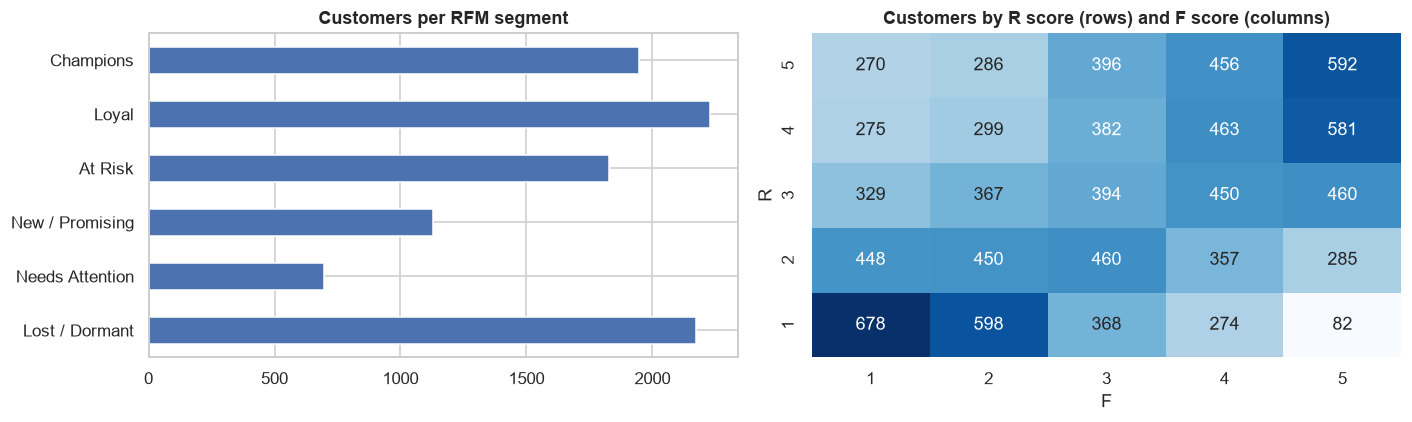

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
seg['customers'].plot.barh(ax=ax[0], color='C0'); ax[0].invert_yaxis(); ax[0].set_title('Customers per RFM segment'); ax[0].set_ylabel('')
sns.heatmap(pd.crosstab(rfm['R'], rfm['F']).sort_index(ascending=False), annot=True, fmt='d', cmap='Blues', ax=ax[1], cbar=False)
ax[1].set_title('Customers by R score (rows) and F score (columns)')
plt.tight_layout(); save('03a_rfm_segments'); plt.show()

**Insights — rule-based RFM**
- The rules produce six segments of fairly even size (7–22% each). *Champions* (19%) spend ~2.5× more than the low-frequency segments.
- **Read the recency-based names with care.** *Lost / Dormant* (22%) and *At Risk* (18%) sound alarming, but these customers last shopped only ~4–6 days ago. No one in this data has actually left (Step 1). The labels only mean "less recent than others", because the quintiles are relative.
- The heatmap shows that recency and frequency are linked: frequent shoppers are naturally more likely to have shopped in the last day or two (top-right), and infrequent shoppers are more likely to have a longer gap (bottom-left).

## 2. Prepare data for K-Means
Recency, Frequency and Monetary are skewed, so they are **log-transformed and standardised** (otherwise the biggest spenders would dominate every cluster).
This is done inside a scikit-learn pipeline (`make_kmeans`), so the saved model can score new customers in one step.

**Which features?** Step 2 showed that Frequency and Monetary are almost the same signal (everyone has the same basket value).
Before committing to the classic R, F, M, we check whether adding behaviour features (basket value, 90-day spend trend) gives clearer groups.

In [4]:
from sklearn.cluster import KMeans
def best_silhouette(X, ks=range(3, 7)):
    Xs = StandardScaler().fit_transform(X)
    scores = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(Xs)) for k in ks}
    k = max(scores, key=scores.get)
    return k, scores[k]

candidates = {
    'R, F, M (log)':                      np.log1p(cust[KMEANS_FEATURES]),
    'R, F (log) + basket value + trend':  pd.concat([np.log1p(cust[['recency_days', 'frequency']]), cust[['aov']],
                                                     cust[['spend_trend_90']].clip(-1, 3)], axis=1),
    'F (log) + basket value + trend':     pd.concat([np.log1p(cust[['frequency']]), cust[['aov']],
                                                     cust[['spend_trend_90']].clip(-1, 3)], axis=1),
}
print('Spearman correlation, frequency vs monetary:', round(cust['frequency'].corr(cust['monetary'], method='spearman'), 3))
pd.DataFrame([(name, *best_silhouette(X)) for name, X in candidates.items()],
             columns=['feature set', 'best k (3-6)', 'silhouette']).set_index('feature set')

Spearman correlation, frequency vs monetary: 0.964


,best k (3-6),silhouette
feature set,,
"R, F, M (log)",6,0.50
"R, F (log) + basket value + trend",5,0.25
F (log) + basket value + trend,4,0.32


The classic **R, F, M** set gives clearly separated groups (silhouette ≈ 0.45–0.5), while adding basket value and spend trend makes the structure much weaker
(those features are mostly noise in this data). So K-Means uses **log R, F, M**. Because F and M move together, frequency effectively counts twice — acceptable here,
since frequency is the main way customers differ.

## 3. Choose k (number of clusters)
Two checks for k = 2 … 10: **inertia** (elbow method: within-cluster spread, lower is tighter) and **silhouette** (how well each customer fits its own cluster vs the next one, higher is better).

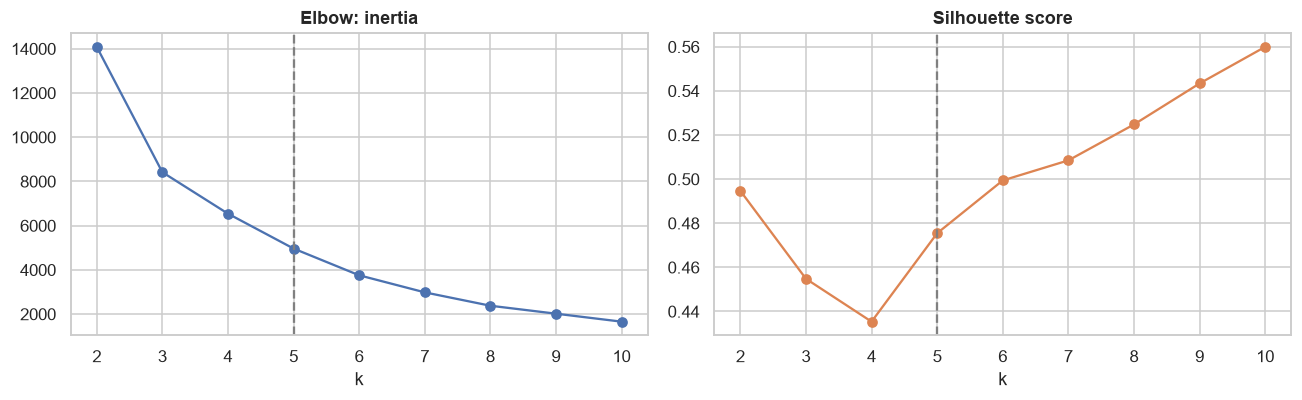

,inertia,silhouette,inertia_drop_%
k,,,
2,"14,085.76",0.49,NaN
3,"8,416.50",0.45,40.25
4,"6,541.94",0.44,22.27
5,"4,964.02",0.48,24.12
6,"3,754.81",0.50,24.36
7,"2,982.79",0.51,20.56
8,"2,377.94",0.52,20.28
9,"2,018.27",0.54,15.13
10,"1,657.63",0.56,17.87


In [5]:
rows = []
for k in range(2, 11):
    pipe = make_kmeans(k).fit(cust[KMEANS_FEATURES])
    Xs = pipe[:-1].transform(cust[KMEANS_FEATURES])
    rows.append({'k': k, 'inertia': pipe[-1].inertia_, 'silhouette': silhouette_score(Xs, pipe[-1].labels_)})
kscores = pd.DataFrame(rows).set_index('k')
kscores['inertia_drop_%'] = -kscores['inertia'].pct_change() * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(kscores.index, kscores['inertia'], 'o-'); ax[0].set_title('Elbow: inertia'); ax[0].set_xlabel('k')
ax[1].plot(kscores.index, kscores['silhouette'], 'o-', color='C1'); ax[1].set_title('Silhouette score'); ax[1].set_xlabel('k')
for a in ax: a.axvline(5, color='grey', ls='--')
plt.tight_layout(); save('03b_choose_k'); plt.show()
kscores

In [6]:
# What would a 6th cluster add? Compare k = 5 and k = 6 profiles
for k in (5, 6):
    lab = make_kmeans(k).fit(cust[KMEANS_FEATURES])[-1].labels_
    p = cust.assign(cluster=lab).groupby('cluster').agg(customers=('frequency', 'size'), recency_days=('recency_days', 'mean'),
                                                        frequency=('frequency', 'mean'), monetary=('monetary', 'mean'))
    display(p.sort_values('frequency', ascending=False).round(1).rename_axis(f'k={k}'))

,customers,recency_days,frequency,monetary
k=5,,,,
3,1020,1.50,"1,072.80","2,261,178.40"
1,1889,1.90,700.70,"1,474,925.50"
0,2377,1.70,468.20,"988,297.30"
2,2317,6.40,370.90,"779,917.10"
4,2397,1.80,327.40,"690,080.10"


,customers,recency_days,frequency,monetary
k=6,,,,
3,1020,1.50,"1,072.80","2,261,178.40"
0,1720,1.60,701.20,"1,476,726.20"
5,1376,4.60,496.40,"1,047,268.20"
2,1883,1.40,467.70,"986,480.90"
1,1613,6.80,328.10,"689,049.50"
4,2388,1.80,327.20,"689,496.10"


**Choosing k = 5**
- **Elbow:** inertia falls steadily (~20–24% per extra cluster up to k = 8) with no sharp bend, so the elbow alone does not pick a k.
- **Silhouette:** it dips from k = 2 to k = 4 and then rises again, and **k = 5 (0.48) beats k = 3 and k = 4**. It keeps rising beyond 5 because recency is measured in whole days, so K-Means can always split a group into "shopped 1–2 days ago" and "shopped 4–7 days ago".
- **What a 6th cluster adds:** the k = 6 table shows that it mainly splits *Slipping Away* by gap length: a mostly-Silver group last seen ~4.6 days ago (which also takes ~170 less-recent Gold customers) and a Bronze group last seen ~6.8 days ago. Both would get the same win-back action, so the extra cluster gives no new decision.
- **Business fit:** 5 segments are few enough for a marketing team to act on, and each gets a distinct action (section 6).

So k = 5 is chosen: it scores best among the small, actionable values of k, and larger k only adds splits by a few days of recency.

## 4. Fit K-Means (k = 5) and name the clusters
Cluster numbers mean nothing to a manager and change between runs, so names are assigned from each cluster's profile (`name_clusters`):
the cluster with the longest time since last visit is **Slipping Away**; the other four are named by visit frequency — **Champions, Loyal, Regulars, Occasional**.

In [7]:
K = 5
km = make_kmeans(K).fit(cust[KMEANS_FEATURES])
names = name_clusters(cust, km[-1].labels_)
rfm['Cluster'] = km[-1].labels_
rfm['Segment'] = pd.Categorical(rfm['Cluster'].map(names), categories=SEG_ORDER, ordered=True)

total_rev = rfm['monetary'].sum()
profile = rfm.groupby('Segment', observed=True).agg(
    customers=('Cluster', 'size'), recency_days=('recency_days', 'mean'), frequency=('frequency', 'mean'),
    monetary=('monetary', 'mean'), aov=('aov', 'mean'), avg_days_between=('avg_days_between', 'mean'),
    overdue_ratio=('overdue_ratio', 'mean'), spend_trend_90=('spend_trend_90', 'mean'), revenue=('monetary', 'sum'))
profile.insert(1, 'share_%', profile['customers'] / len(rfm) * 100)
profile['revenue_share_%'] = profile.pop('revenue') / total_rev * 100
profile

,customers,share_%,recency_days,frequency,monetary,aov,avg_days_between,overdue_ratio,spend_trend_90,revenue_share_%
Segment,,,,,,,,,,
Champions,1020,10.20,1.52,"1,072.80","2,261,178.39","2,107.67",1.36,1.12,0.26,21.15
Loyal,1889,18.89,1.94,700.67,"1,474,925.52","2,105.16",2.09,0.93,0.27,25.55
Regulars,2377,23.77,1.74,468.18,"988,297.32","2,110.82",3.12,0.56,0.33,21.55
Occasional,2397,23.97,1.81,327.36,"690,080.14","2,108.17",4.47,0.41,0.39,15.17
Slipping Away,2317,23.17,6.39,370.85,"779,917.14","2,102.90",4.05,1.61,0.29,16.57


In [8]:
mix = pd.crosstab(rfm['Segment'], rfm['loyalty_segment'], normalize='index')[TIERS] * 100
mix.round(1).astype(str) + '%'

loyalty_segment,Bronze,Silver,Gold,Platinum
Segment,,,,
Champions,0.0%,0.0%,0.0%,100.0%
Loyal,0.0%,0.0%,100.0%,0.0%
Regulars,0.1%,99.9%,0.0%,0.0%
Occasional,99.9%,0.1%,0.0%,0.0%
Slipping Away,67.8%,31.5%,0.7%,0.0%


**Insights — segment profiles**
- **K-Means rediscovers the loyalty tiers:** Champions = 100% Platinum, Loyal = 100% Gold, Regulars ≈ 100% Silver, Occasional ≈ 100% Bronze. Visit frequency is what the loyalty programme rewards, and it is also the main way customers differ.
- **The new information is the 5th segment, *Slipping Away* (23% of customers, mostly Bronze and Silver).** These customers last shopped ~6.4 days ago, versus ~1.5–2 days for the other segments, and their overdue ratio is 1.6 (they are 60% later than their usual gap). The loyalty tier alone does not show this.
- Basket value is the same in every segment (~PKR 2,100). Segments differ in **how often** customers shop, not how much they buy per visit.
- **Champions are 10% of customers but 21% of revenue;** Champions + Loyal together are 29% of customers and 47% of revenue.
- *Slipping Away* customers are behind on visits but are **not** spending less over 90 days (spend trend +29%, similar to the others). This is a short-term signal; Step 4 tests whether it predicts a real drop in spend.

## 5. Visualise and validate the segments

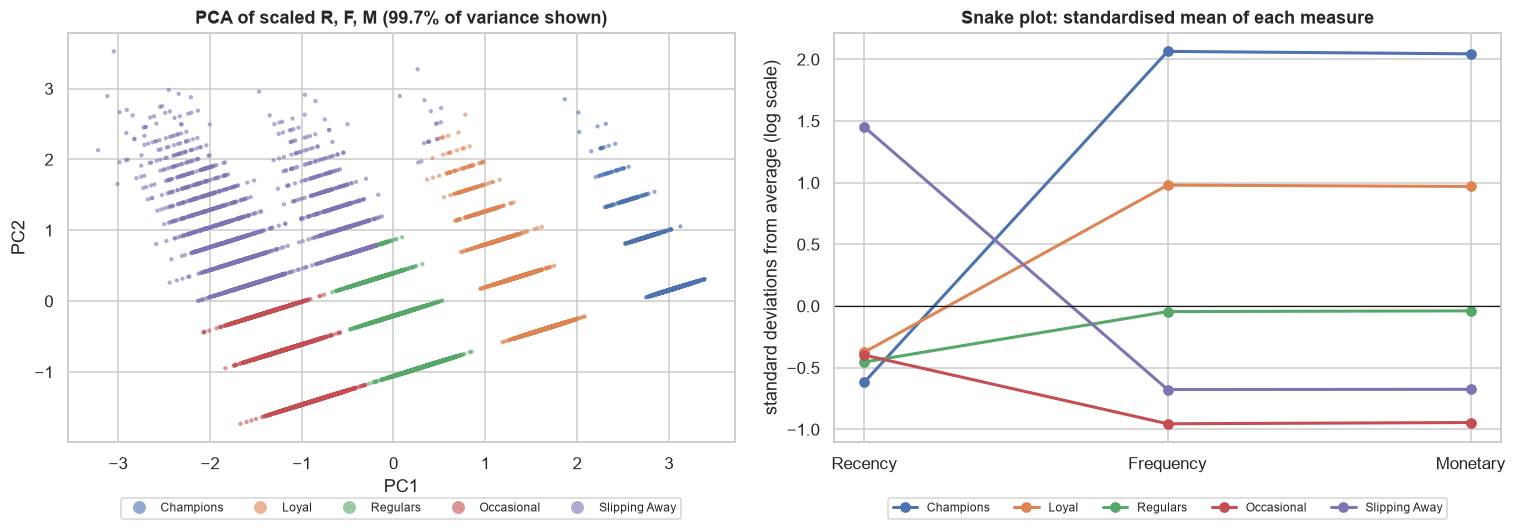

In [9]:
Xs = km[:-1].transform(cust[KMEANS_FEATURES])
pcs = PCA(n_components=2, random_state=42).fit(Xs)
pts = pcs.transform(Xs)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=rfm['Segment'], hue_order=SEG_ORDER, s=8, alpha=.6, ax=ax[0], linewidth=0)
ax[0].set_title(f'PCA of scaled R, F, M ({pcs.explained_variance_ratio_.sum():.1%} of variance shown)')
ax[0].set_xlabel('PC1'); ax[0].set_ylabel('PC2'); ax[0].legend(markerscale=3, title='', loc='upper center', bbox_to_anchor=(.5, -.12), ncol=5, fontsize=8)

snake = pd.DataFrame(Xs, columns=['Recency', 'Frequency', 'Monetary'], index=rfm.index).groupby(rfm['Segment'], observed=True).mean()
for s in SEG_ORDER: ax[1].plot(snake.columns, snake.loc[s], 'o-', label=s, lw=2)
ax[1].axhline(0, color='k', lw=.8); ax[1].set_title('Snake plot: standardised mean of each measure')
ax[1].set_ylabel('standard deviations from average (log scale)')
ax[1].legend(title='', loc='upper center', bbox_to_anchor=(.5, -.12), ncol=5, fontsize=8)
plt.tight_layout(); save('03c_segments_pca_snake'); plt.show()

**Cross-check with the rule-based RFM segments.** If the two methods broadly agree, the clusters reflect real differences rather than an artefact of the algorithm.

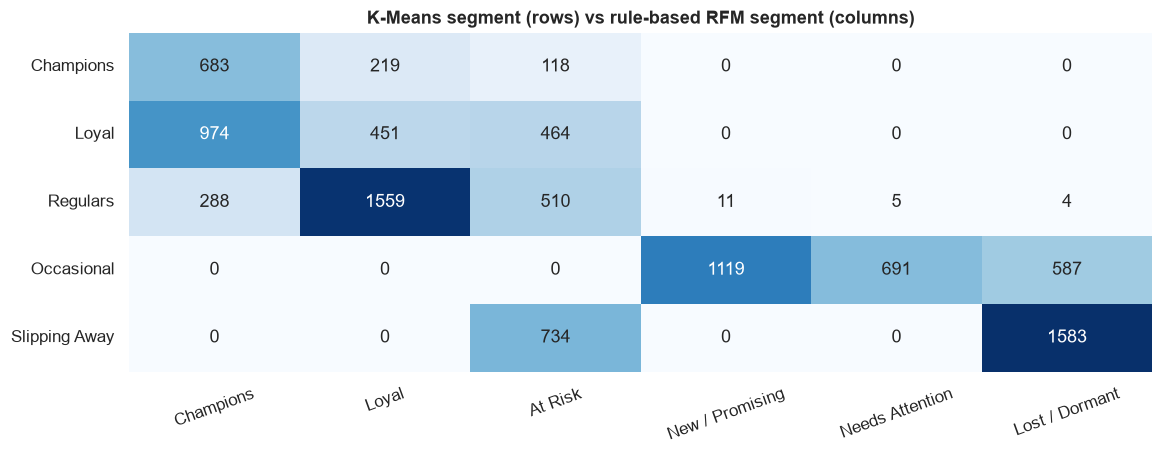

In [10]:
ct = pd.crosstab(rfm['Segment'], rfm['RFM_Segment'])
ct = ct[seg.index]                                     # RFM segments ordered by spend
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
ax.set_title('K-Means segment (rows) vs rule-based RFM segment (columns)'); ax.set_xlabel(''); ax.set_ylabel('')
plt.xticks(rotation=20); save('03d_kmeans_vs_rfm'); plt.show()

**Stability and an alternative algorithm.** A good segmentation should not change much with the random starting point,
and a different clustering method should find similar groups. Agreement is measured with the adjusted Rand index (ARI: 1 = identical, 0 = random).

In [11]:
seeds = [make_kmeans(K, random_state=s).fit(cust[KMEANS_FEATURES])[-1].labels_ for s in range(5)]
seed_ari = [adjusted_rand_score(seeds[0], s) for s in seeds[1:]]

sample = rfm.sample(4000, random_state=42).index
pos = rfm.index.get_indexer(sample)
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(Xs[pos])
pd.DataFrame({
    'check': ['K-Means with 4 other random seeds (min ARI)', 'Agglomerative (Ward) vs K-Means, 4,000-customer sample',
              'K-Means vs rule-based RFM segments', 'K-Means vs loyalty tier'],
    'ARI': [min(seed_ari), adjusted_rand_score(rfm['Cluster'].iloc[pos], agg),
            adjusted_rand_score(rfm['Segment'], rfm['RFM_Segment']), adjusted_rand_score(rfm['Segment'], rfm['loyalty_segment'])],
}).set_index('check')

,ARI
check,
K-Means with 4 other random seeds (min ARI),1.00
"Agglomerative (Ward) vs K-Means, 4,000-customer sample",0.98
K-Means vs rule-based RFM segments,0.36
K-Means vs loyalty tier,0.65


**Insights — validation**
- **Very stable:** five different random seeds give identical clusters (ARI = 1.00), and Agglomerative (Ward) clustering finds almost the same groups (ARI = 0.98). The segments are a real structure in the data, not an accident of the algorithm. K-Means is kept because it gives the same answer and can assign new customers with `predict` (Agglomerative cannot).
- The PCA view captures essentially all of the variance in 2 dimensions, because Frequency and Monetary are almost the same measure. The striped pattern comes from recency being whole days.
- **Agreement with the rule-based RFM is moderate (ARI = 0.36), and the cross-tab shows why.** The RFM rules split customers by small recency differences: K-Means *Loyal* customers are spread across RFM *Champions*, *Loyal* and *At Risk*. K-Means instead groups customers by their overall shopping rhythm. Both methods agree on the extremes: K-Means *Occasional* customers are all in the low-frequency RFM segments, and *Slipping Away* maps to *At Risk* or *Lost / Dormant*.
- For the dashboard and the business actions, the **K-Means segments are the main segmentation**. They are stable, they line up with the loyalty programme, and they add the *Slipping Away* group. The RFM scores are kept as an extra column.

## 6. Business actions and outputs

In [12]:
actions = pd.DataFrame([(s, *SEGMENT_ACTIONS[s]) for s in SEG_ORDER], columns=['Segment', 'Who they are', 'Recommended action']).set_index('Segment')
actions = actions.join(profile[['customers', 'share_%', 'revenue_share_%']])
actions

,Who they are,Recommended action,customers,share_%,revenue_share_%
Segment,,,,,
Champions,"Shop almost daily, highest spend","VIP perks, early access to new products, refer...",1020,10.20,21.15
Loyal,"Shop every 2 days, high spend",Bundles and cross-sell to move them up to Cham...,1889,18.89,25.55
Regulars,"Shop every 3 days, mid spend",Personalised offers in categories they already...,2377,23.77,21.55
Occasional,"Shop every 4-5 days, lowest spend",Visit-frequency incentives (e.g. points for a ...,2397,23.97,15.17
Slipping Away,Longer than usual since last visit,"Timely win-back message with a small, time-lim...",2317,23.17,16.57


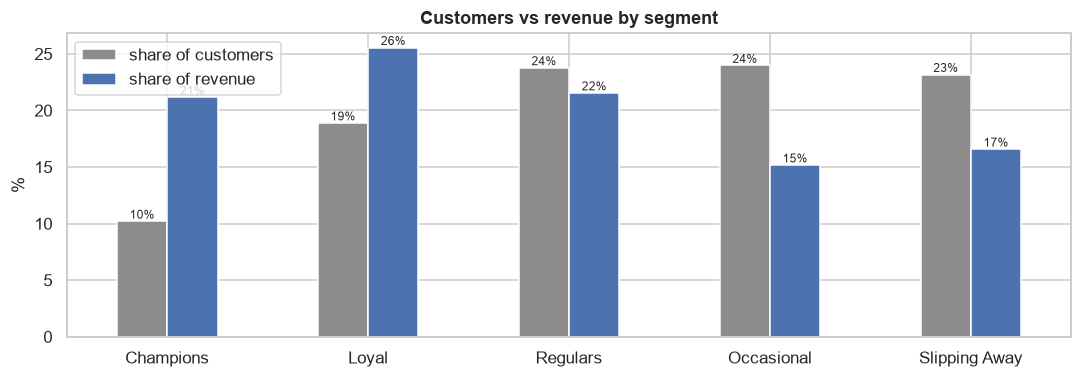

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.6))
share = profile[['share_%', 'revenue_share_%']].rename(columns={'share_%': 'share of customers', 'revenue_share_%': 'share of revenue'})
share.plot.bar(ax=ax, rot=0, color=['C7', 'C0'])
ax.set_ylabel('%'); ax.set_xlabel(''); ax.set_title('Customers vs revenue by segment')
for c in ax.containers: ax.bar_label(c, fmt='%.0f%%', fontsize=8)
plt.tight_layout(); save('03e_segment_value'); plt.show()

In [14]:
keep = ['recency_days', 'frequency', 'monetary', 'aov', 'avg_days_between', 'overdue_ratio', 'spend_trend_90',
        'loyalty_segment', 'preferred_channel', 'city', 'R', 'F', 'M', 'RFM_Score', 'RFM_Segment', 'Cluster', 'Segment']
rfm[keep].to_csv(PROC / 'customer_segments.csv', index_label='customer_id', float_format=FLOAT)
joblib.dump({'model': km, 'features': KMEANS_FEATURES, 'names': names}, MODELS / 'kmeans_segments.pkl')

# Check the saved model reproduces the segments
saved = joblib.load(MODELS / 'kmeans_segments.pkl')
again = pd.Series(saved['model'].predict(cust[saved['features']]), index=cust.index).map(saved['names'])
assert (again == rfm['Segment'].astype(str)).all()
print('saved customer_segments.csv', rfm[keep].shape, 'and models/kmeans_segments.pkl (pipeline + feature list + names)')

saved customer_segments.csv (10000, 17) and models/kmeans_segments.pkl (pipeline + feature list + names)


**Done-when check (Step 3)**
- ✅ Every customer has a named segment (K-Means) plus RFM scores and an RFM segment → `data/processed/customer_segments.csv`
- ✅ k is justified with the elbow and silhouette charts, plus the k = 6 comparison (`reports/figures/03b_choose_k.png`)
- ✅ PCA scatter, snake plot, cross-tab against RFM, and a check against an alternative algorithm
- ✅ Business action table written; model saved as `models/kmeans_segments.pkl` (log + scaler + K-Means pipeline, feature list and segment names). A reload check confirms it reproduces the segments.

**Carry forward**
- **Step 4 (churn):** use the segment as a feature and report the churn rate and revenue at risk per segment. "High-risk Champions" are the first customers to contact.
- **Dashboard (Step 8):** load `kmeans_segments.pkl` and call `predict` on new customer features; use `SEGMENT_ACTIONS` from `src/segmentation.py` for the action text.